# DELE CA1 Part A

WGAN IS NOT FULLY RUN BECAUSE OUT OF TIME


Kazu did initial EDA and preprocessing 

Enzo created the models, DCGAN and WGAN

In [213]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from PIL import Image

from collections import Counter

from scipy.linalg import sqrtm
from tensorflow.keras.applications.inception_v3 import InceptionV3, preprocess_input

import tensorflow as tf
from tensorflow.keras import layers

from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split

In [214]:
df = pd.read_csv("C:/Users/Enzo/schEnzo/OneDrive - Singapore Polytechnic/Code/DELE/emnist-letters-train.csv")
# df = pd.read_csv("C:/Users/tayen\OneDrive - Singapore Polytechnic/Code/DELE/emnist-letters-train.csv")

# Show the first few rows
print(df.head())

# Shape of dataset
print("Shape:", df.shape)  

# Info summary of dataset (columns, non-null counts, datatypes, memory)
print("\n", df.info())

   24    0  0.1  0.2  0.3  0.4  0.5  0.6  0.7  0.8  ...  0.552  0.553  0.554  \
0  -2  142  142  142  142  142  142  142  142  142  ...    142    142    142   
1  15    0    0    0    0    0    0    0    0    0  ...      0      0      0   
2  14    0    0    0    0    0    0    0    0    0  ...      0      0      0   
3  -2  120  120  120  120  120  120  120  120  120  ...    120    120    120   
4  -1  131  131  131  131  131  131  131  131  200  ...    131    131    131   

   0.555  0.556  0.557  0.558  0.559  0.560  0.561  
0    142    142    142    142    142    142    142  
1      0      0      0      0      0      0      0  
2      0      0      0      0      0      0      0  
3    120    120    120    120    120    120    120  
4    131    131    131    131    131    131    131  

[5 rows x 785 columns]
Shape: (64828, 785)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64828 entries, 0 to 64827
Columns: 785 entries, 24 to 0.561
dtypes: int64(785)
memory usage: 388.3 MB

 Non

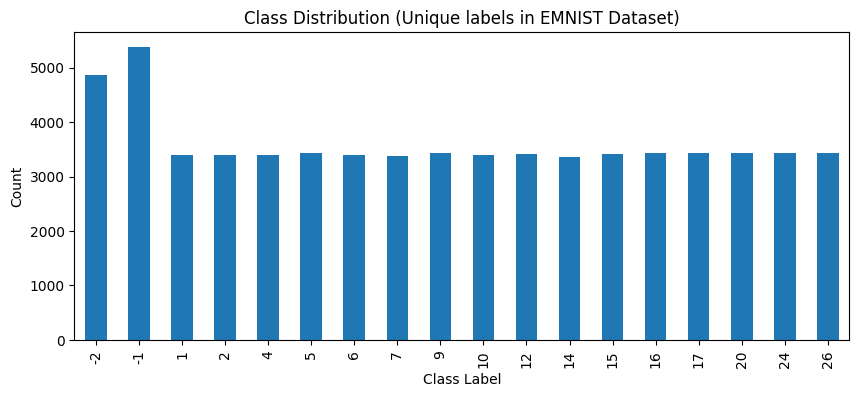

Unique labels in dataset: [-2, -1, 1, 2, 4, 5, 6, 7, 9, 10, 12, 14, 15, 16, 17, 20, 24, 26]


In [215]:
labels = df.iloc[:, 0]  # First column is label (1 to 26 for A-Z)

plt.figure(figsize=(10, 4))
labels.value_counts().sort_index().plot(kind='bar')
plt.title("Class Distribution (Unique labels in EMNIST Dataset)")
plt.xlabel("Class Label")
plt.ylabel("Count")
plt.show()

print("Unique labels in dataset:", sorted(df.iloc[:, 0].unique()))

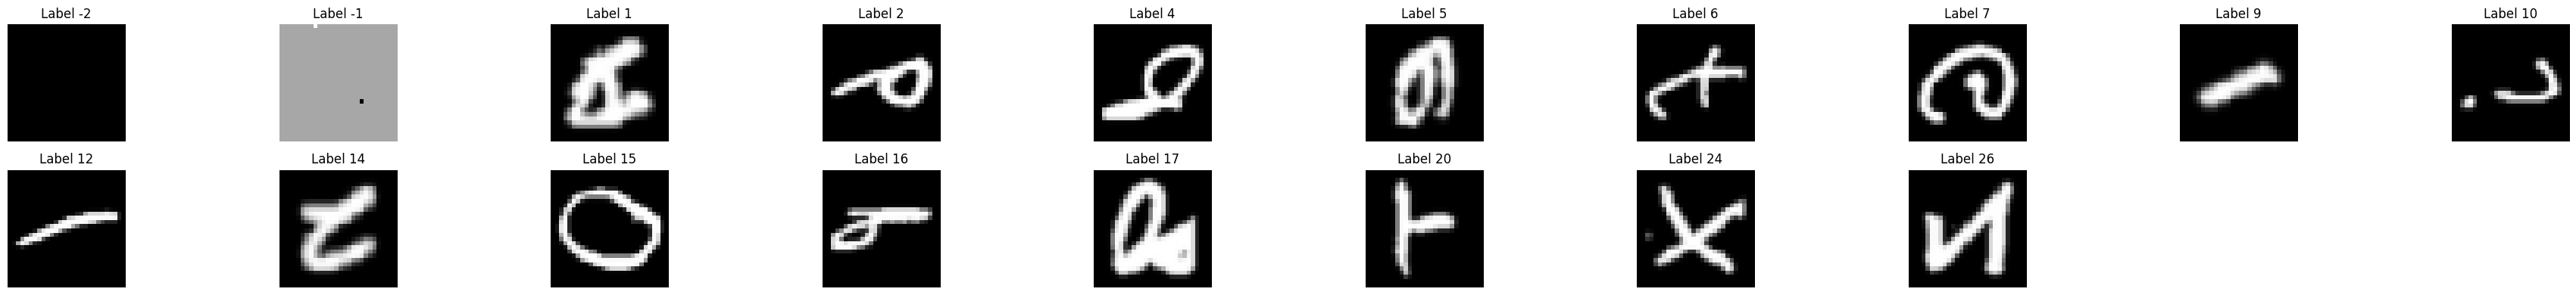

In [216]:
available_labels = sorted(df.iloc[:, 0].unique())

plt.figure(figsize=(len(available_labels) * 2, 4))  # Adjust figure width dynamically
for i, label in enumerate(available_labels):
    img = df[df.iloc[:, 0] == label].iloc[0, 1:].values.reshape(28, 28)
    plt.subplot(2, len(available_labels) // 2 + 1, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(f"Label {label}")
    plt.axis('off')

plt.tight_layout()
plt.show()

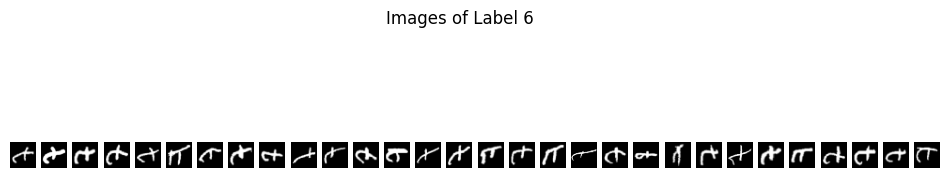

In [217]:
label_to_show = 6
subset = df[df.iloc[:, 0] == label_to_show]

plt.figure(figsize=(12, 3))
for i in range(30):
    img = subset.iloc[i, 1:].values.reshape(28, 28)
    plt.subplot(1, 30, i + 1)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
plt.suptitle(f"Images of Label {label_to_show}")
plt.show()


In [218]:
labels = df.iloc[:, 0].values

# Filter out invalid labels, e.g. negative values
valid_labels_mask = labels >= 0
labels = labels[valid_labels_mask]

# Extract and reshape image pixels
X_filtered = df.iloc[valid_labels_mask, 1:].values.astype('float32')  # before reshape, for stats

# Compute mean and std before normalization
pixel_mean_raw = X_filtered.mean()
pixel_std_raw = X_filtered.std()
print("Raw pixel mean:", pixel_mean_raw)
print("Raw pixel std:", pixel_std_raw)

# --- Now map numeric labels to letters and index ---

# Manual mapping from numeric label to letter
manual_label_map = {
    1: 'A',
    2: 'B',
    4: 'D',
    5: 'E',
    6: 'F',
    7: 'G',
    9: 'I',
    10: 'J',
    12: 'L',
    14: 'N',
    15: 'O',
    16: 'P',
    17: 'Q',
    20: 'T',
    24: 'X',
    26: 'Z'
}

# Map numeric labels to letter labels
letter_labels = np.array([manual_label_map[label] for label in labels])

# Define fixed letter order for indexing
letters = ['A', 'B', 'D', 'E', 'F', 'G', 'I', 'J', 'L', 'N', 'O', 'P', 'Q', 'T', 'X', 'Z']
letter_to_index = {letter: idx for idx, letter in enumerate(letters)}

# Map letter labels to numeric indices directly (no function)
indexed_labels = np.array([letter_to_index[letter] for letter in letter_labels])

# Print the mapping dictionary only
print("Manual letter_to_index mapping:", letter_to_index)

Raw pixel mean: 43.943172
Raw pixel std: 84.49391
Manual letter_to_index mapping: {'A': 0, 'B': 1, 'D': 2, 'E': 3, 'F': 4, 'G': 5, 'I': 6, 'J': 7, 'L': 8, 'N': 9, 'O': 10, 'P': 11, 'Q': 12, 'T': 13, 'X': 14, 'Z': 15}


In [219]:
# Normalize to [-1, 1] for GANs
X_filtered = (X_filtered - 127.5) / 127.5

X_filtered = X_filtered.reshape(-1, 28, 28, 1)

# Sanity checke)
print("Pixel mean:", X_filtered.mean())
print("Pixel std:", X_filtered.std())

Pixel mean: -0.65534747
Pixel std: 0.6626988


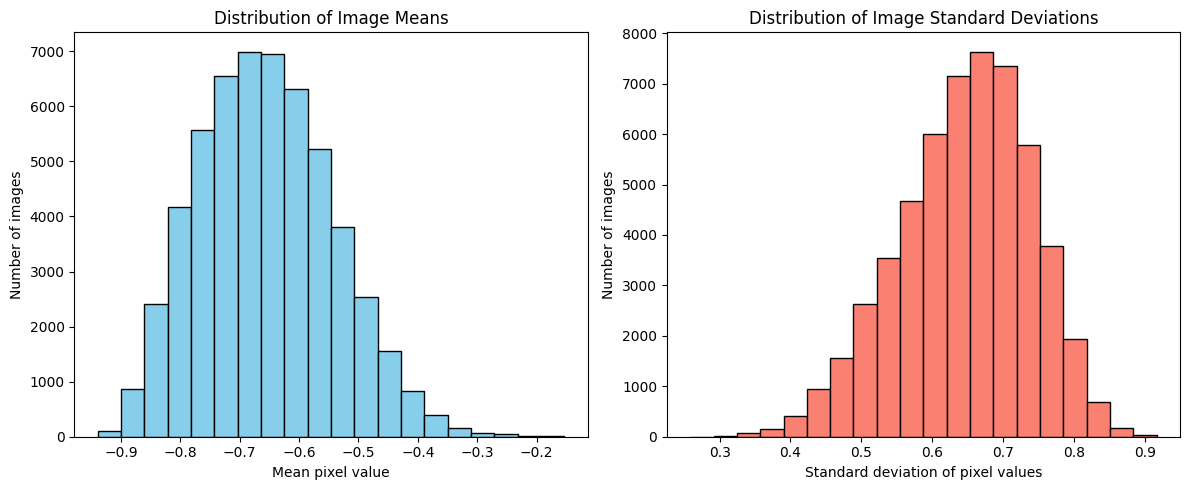

In [220]:
image_means = X_filtered.reshape(X_filtered.shape[0], -1).mean(axis=1)
image_stds = X_filtered.reshape(X_filtered.shape[0], -1).std(axis=1)
plt.figure(figsize=(12, 5))

# Histogram of image means
plt.subplot(1, 2, 1)
plt.hist(image_means, bins=20, color='skyblue', edgecolor='black')
plt.title('Distribution of Image Means')
plt.xlabel('Mean pixel value')
plt.ylabel('Number of images')

# Histogram of image std deviations
plt.subplot(1, 2, 2)
plt.hist(image_stds, bins=20, color='salmon', edgecolor='black')
plt.title('Distribution of Image Standard Deviations')
plt.xlabel('Standard deviation of pixel values')
plt.ylabel('Number of images')

plt.tight_layout()
plt.show()

In [221]:
def apply_rotation(images, labels):
    rotated_images = []
    
    # Labels that need 90° CW rotation and flip
    rotate_and_flip_labels = {1, 2, 4, 5, 6, 7, 9, 10, 12, 14, 15, 16, 17, 20, 24, 26}

    for img, label in zip(images, labels):
        img = img.reshape(28, 28)
        
        if label in rotate_and_flip_labels:
            img = np.rot90(img, k=3)      # 90° clockwise
            img = np.fliplr(img)         # Flip left-right

        rotated_images.append(img)
    
    rotated_images = np.array(rotated_images).astype('float32')
    rotated_images = np.expand_dims(rotated_images, -1)  # Add channel dimension for grayscale
    return rotated_images

# Apply rotation + flip
X_filtered = apply_rotation(X_filtered, labels)

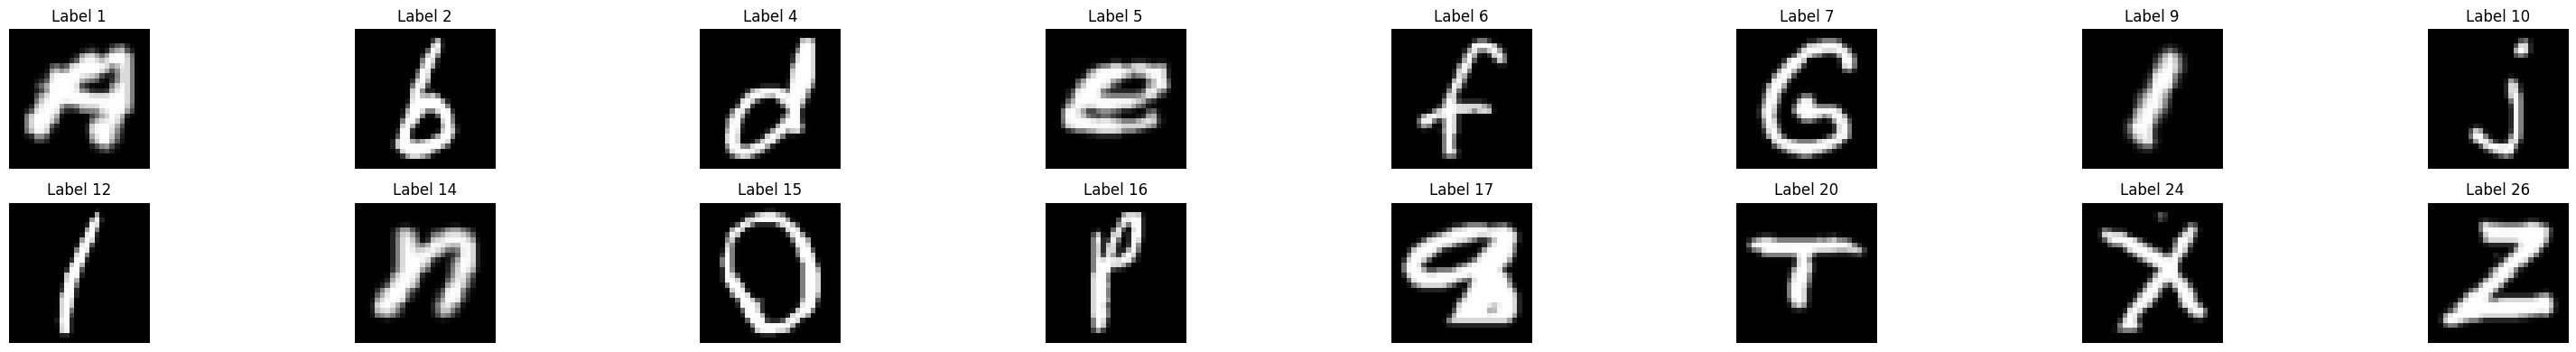

In [222]:
available_labels = sorted(np.unique(labels))

plt.figure(figsize=(len(available_labels) * 2, 4))  # Dynamic width based on number of labels

for i, label in enumerate(available_labels):
    # Find the first image index with this label
    idx = np.where(labels == label)[0][0]
    img = X_filtered[idx].reshape(28, 28)
    
    plt.subplot(2, (len(available_labels) + 1) // 2, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(f"Label {label}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [223]:
BUFFER_SIZE = 10000
BATCH_SIZE = 128

train_dataset = tf.data.Dataset.from_tensor_slices(X_filtered) \
    .shuffle(BUFFER_SIZE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)

# # Split before creating tf.data.Dataset 
# X_train, X_val, y_train, y_val = train_test_split(
#     X_filtered, mapped_labels, test_size=0.2, random_state=42, stratify=mapped_labels
# )

# # Create tf.data.Dataset objects
# train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(BUFFER_SIZE).batch(BATCH_SIZE)
# val_dataset = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE)
# NOT SURE IF SHOULD SPLIT DATAAAAAA 

In [224]:
def show_generated_images(generator, noise_dim, epoch, seed_noise=None):
    if seed_noise is not None:
        noise = seed_noise
    else:
        noise = tf.random.normal([25, noise_dim])

    fake_images = generator(noise, training=False)
    fake_images_scaled = (fake_images + 1) / 2.0

    for i in range(25):
        plt.subplot(5, 5, i + 1)
        plt.imshow(fake_images_scaled[i, :, :, 0], cmap='gray')
        plt.axis('off')
    plt.suptitle(f'Generated Images (Epoch {epoch})')
    plt.tight_layout()
    plt.show()

In [225]:
# USES FID ONLY FOR EVALUATION

# Load Inception model once globally
inception_model = InceptionV3(include_top=False, pooling='avg', input_shape=(299, 299, 3))

def resize_and_rgb(images, size=299):
    resized = []
    for img in images:
        # Convert Tensor to NumPy if needed
        if isinstance(img, tf.Tensor):
            img = img.numpy()
        img_arr = np.squeeze(img)  # Now it's always a NumPy array
        img_pil = Image.fromarray((img_arr * 255).astype(np.uint8))
        img_resized = img_pil.resize((size, size), Image.BILINEAR)
        img_rgb = img_resized.convert('RGB')
        resized.append(np.array(img_rgb))
    return np.array(resized)
def preprocess_images_for_inception(images):
    # images expected shape: (N,H,W,3) scaled 0-1 float32
    return preprocess_input(images * 255.0)

def get_activations(images, model=inception_model, batch_size=50):
    activations = []
    n_batches = int(np.ceil(len(images) / batch_size))
    for i in range(n_batches):
        batch = images[i * batch_size:(i + 1) * batch_size]
        batch_pp = preprocess_images_for_inception(batch)
        act = model(batch_pp)
        activations.append(act.numpy())
    return np.vstack(activations)

def calculate_fid(real_images, generated_images):
    act1 = get_activations(real_images)
    act2 = get_activations(generated_images)

    mu1, sigma1 = act1.mean(axis=0), np.cov(act1, rowvar=False)
    mu2, sigma2 = act2.mean(axis=0), np.cov(act2, rowvar=False)

    ssdiff = np.sum((mu1 - mu2)**2)
    covmean = sqrtm(sigma1.dot(sigma2))
    if np.iscomplexobj(covmean):
        covmean = covmean.real

    fid = ssdiff + np.trace(sigma1 + sigma2 - 2 * covmean)
    return fid

def evaluate_gan(generator, discriminator, noise_dim, real_images, epoch=0, 
                 class_labels=None, generated_labels=None, seed_noise=None,
                 precision_history=None, recall_history=None,
                 gen_loss_history=None, disc_loss_history=None):

    print("===== Final GAN Evaluation =====")
    
    # Step 1: Generate fake images
    if seed_noise is not None:
        noise = seed_noise
    else:
        noise = tf.random.normal([100, noise_dim])

    fake_images = generator(noise, training=False)
    fake_images_scaled = (fake_images + 1) / 2.0

    # Match real image count to fake image count
    num_fake = fake_images.shape[0]
    real_images = real_images[:num_fake]
    if class_labels is not None:
        class_labels = class_labels[:num_fake]

    # Step 2: Discriminator score
    disc_scores = discriminator(fake_images, training=False)
    avg_disc_score = tf.reduce_mean(disc_scores).numpy()

    # Step 3: Pixel stats
    real_scaled = (real_images + 1) / 2.0 if real_images.min() < 0 else real_images / 255.0
    fake_mean, fake_std = fake_images_scaled.numpy().mean(), fake_images_scaled.numpy().std()
    real_mean, real_std = real_scaled.mean(), real_scaled.std()

    print(f"Epoch: {epoch}")
    print(f"Avg Discriminator Confidence: {avg_disc_score:.4f}")
    print(f"Real Images - Mean: {real_mean:.4f}, Std: {real_std:.4f}")
    print(f"Fake Images - Mean: {fake_mean:.4f}, Std: {fake_std:.4f}")

    # Step 4: Show letter label distribution if class_labels provided
    if class_labels is not None:
        letter_counts = dict(Counter(class_labels))
        print(f"Real Image Class Distribution (letters): {letter_counts}")

    # Step 5: Compute and print FID
    real_for_fid = resize_and_rgb(real_scaled)
    fake_for_fid = resize_and_rgb(fake_images_scaled) 

    fid_score = calculate_fid(real_for_fid, fake_for_fid)
    print(f"FID Score: {fid_score:.4f}")

    # Step 6: t-SNE visualization only (no UMAP)
    real_images_flat = real_scaled.reshape(real_scaled.shape[0], -1)
    fake_images_flat = fake_images_scaled.numpy().reshape(fake_images.shape[0], -1)
    X = np.vstack([real_images_flat, fake_images_flat])
    y = np.array([0] * real_images.shape[0] + [1] * fake_images.shape[0])

    tsne = TSNE(n_components=2, random_state=42, perplexity=30)
    X_tsne = tsne.fit_transform(X)

    plt.figure(figsize=(7, 6))
    plt.scatter(X_tsne[y == 0, 0], X_tsne[y == 0, 1], label=f'Real ({np.sum(y == 0)})', alpha=0.2)
    plt.scatter(X_tsne[y == 1, 0], X_tsne[y == 1, 1], label=f'Fake ({np.sum(y == 1)})', alpha=0.2)
    plt.title('t-SNE Visualization of Real vs Generated Images')
    plt.legend()
    plt.show()

    # Step 7: Plot Precision and Recall over epochs if history provided
    if precision_history and recall_history:
        plt.figure(figsize=(8,5))
        plt.plot(range(1, len(precision_history)+1), precision_history, label='Precision')
        plt.plot(range(1, len(recall_history)+1), recall_history, label='Recall')
        plt.xlabel('Epoch')
        plt.ylabel('Score')
        plt.title('Precision and Recall over Epochs')
        plt.legend()
        plt.show()

    if gen_loss_history and disc_loss_history:
        plt.figure(figsize=(8,5))
        plt.plot(range(1, len(gen_loss_history)+1), gen_loss_history, label='Generator Loss')
        plt.plot(range(1, len(disc_loss_history)+1), disc_loss_history, label='Discriminator Loss')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Generator and Discriminator Loss over Epochs')
        plt.legend()
        plt.show()

    # Step 8: Optional label stats for generated images
    if generated_labels is not None:
        print("Generated class distribution:", dict(Counter(generated_labels)))

In [233]:
def calculate_precision_recall(discriminator, real_images, fake_images, threshold=0.5):
    # Get discriminator scores
    real_scores = discriminator(real_images, training=False)
    fake_scores = discriminator(fake_images, training=False)

    all_scores = tf.concat([real_scores, fake_scores], axis=0)
    min_score = tf.reduce_min(all_scores)
    max_score = tf.reduce_max(all_scores)

    real_probs = (real_scores - min_score) / (max_score - min_score + 1e-8)
    fake_probs = (fake_scores - min_score) / (max_score - min_score + 1e-8)

    # Now apply threshold
    real_preds = tf.cast(real_probs > 0.5, tf.int32)
    fake_preds = tf.cast(fake_probs < 0.5, tf.int32)


    # Precision = TP / (TP + FP)
    # TP: fake images correctly classified as fake (discriminator predicts fake -> 0)
    # but usually in GAN precision/recall are adapted as:
    # Precision = (# fake images predicted fake) / (# total predicted fake)
    # For simplicity:
    TP = np.sum(fake_preds == False)  # Fake images predicted as fake
    FP = np.sum(real_preds == False)  # Real images predicted as fake (false positive)
    precision = TP / (TP + FP + 1e-8)

    # Recall = TP / (TP + FN)
    FN = np.sum(fake_preds == True)   # Fake images predicted as real (false negative)
    recall = TP / (TP + FN + 1e-8)

    return precision, recall

In [227]:
# === 2. Generator Model ===
def make_generator_model():
    model = tf.keras.Sequential([
        layers.Dense(7*7*512, use_bias=False, input_shape=(256,)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Reshape((7, 7, 512)), 
        layers.Conv2DTranspose(256, (5, 5), strides=(1, 1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(128, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(32, (3, 3), strides=(1, 1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(1, (3, 3), strides=(1, 1), padding='same', use_bias=False, activation='tanh')
    ])
    return model

# === 3. Discriminator Model ===
def make_discriminator_model():
    model = tf.keras.Sequential([
        layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same', input_shape=[28, 28, 1]),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(256, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1)
    ])
    return model

# === 4. Loss & Optimizer ===
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

generator = make_generator_model()
discriminator = make_discriminator_model()

generator_optimizer = tf.keras.optimizers.Adam(1e-4)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)


Epoch 1/3
Generator Loss: 1.4563, Discriminator Loss: 0.9051
Precision: 0.5388, Recall: 0.4609


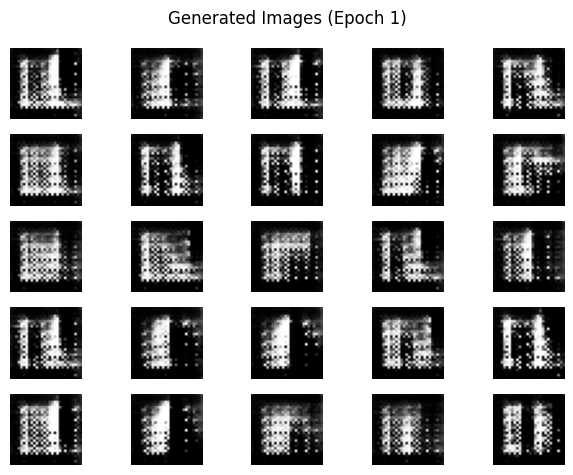


Epoch 2/3
Generator Loss: 1.2403, Discriminator Loss: 1.0652
Precision: 0.8115, Recall: 0.9922


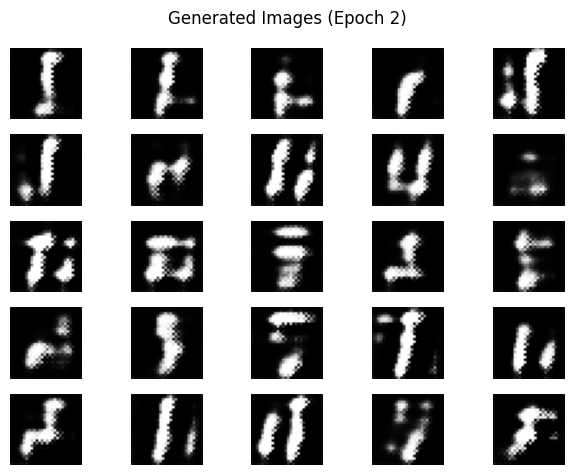


Epoch 3/3
Generator Loss: 1.3240, Discriminator Loss: 1.0180
Precision: 0.8375, Recall: 0.9258


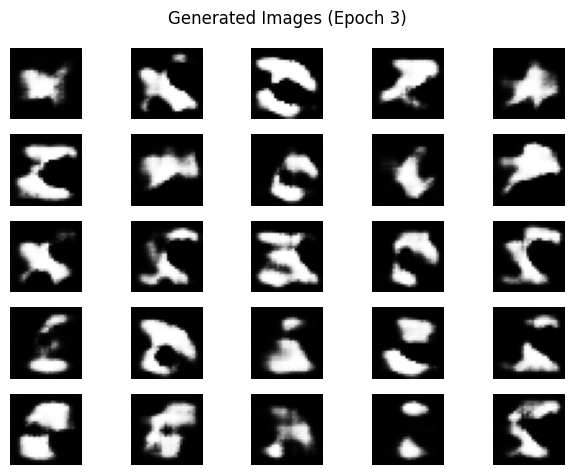

===== Final GAN Evaluation =====
Epoch: 3
Avg Discriminator Confidence: -1.3695
Real Images - Mean: 0.1710, Std: 0.3303
Fake Images - Mean: 0.2285, Std: 0.3714
FID Score: 668056.7089


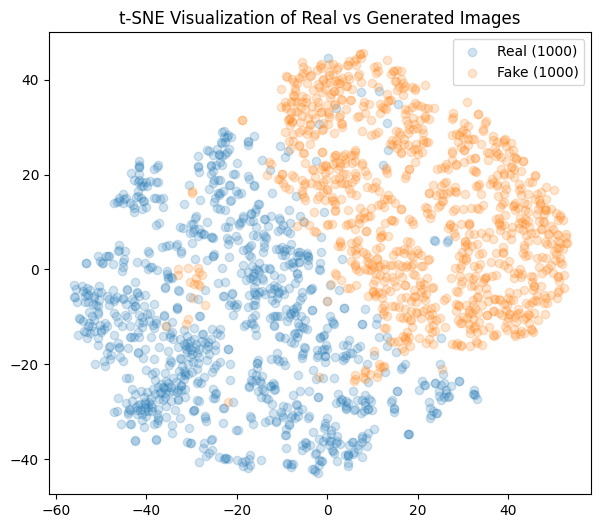

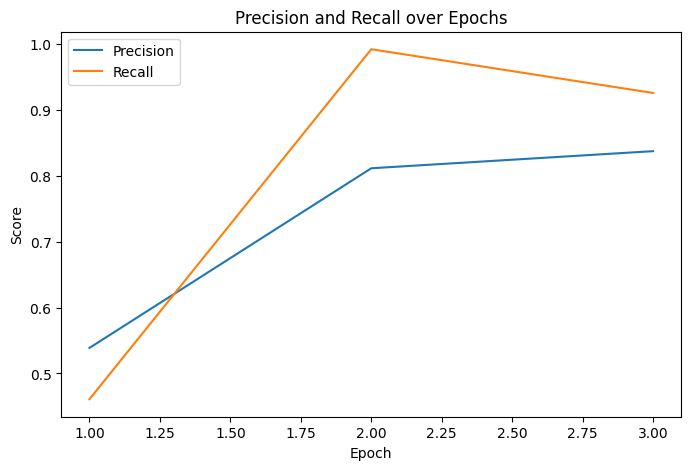

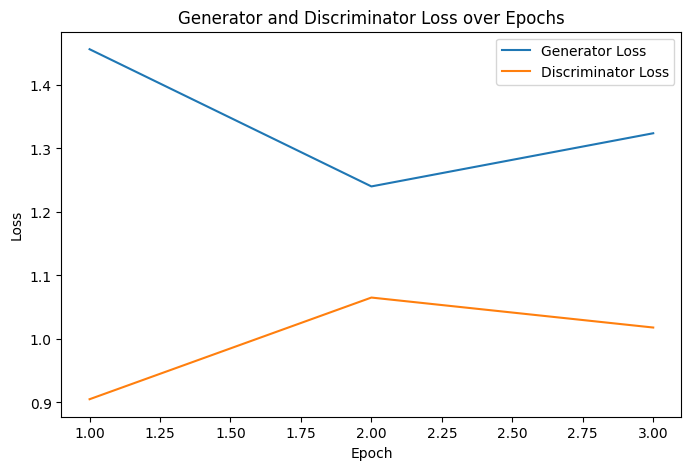

In [228]:
# === 5. Training Loop ===
EPOCHS = 3
noise_dim = 256

gen_loss_history = []
disc_loss_history = []
precision_history = []
recall_history = []

# === Seed for evaluation (e.g., t-SNE, metrics) ===
eval_seed = tf.random.normal([1000, noise_dim])

@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, noise_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    return gen_loss, disc_loss

def train(dataset, epochs, real_images):
    for epoch in range(epochs):
        print(f"\nEpoch {epoch + 1}/{epochs}")
        epoch_gen_loss = []
        epoch_disc_loss = []

        for image_batch in dataset:
            gen_loss, disc_loss = train_step(image_batch)
            epoch_gen_loss.append(gen_loss.numpy())
            epoch_disc_loss.append(disc_loss.numpy())

        # Record average losses
        gen_loss_history.append(np.mean(epoch_gen_loss))
        disc_loss_history.append(np.mean(epoch_disc_loss))

        # Evaluate precision & recall
        noise = tf.random.normal([min(256, len(real_images)), noise_dim])
        fake_images = generator(noise, training=False)
        real_subset = real_images[:fake_images.shape[0]]
        precision, recall = calculate_precision_recall(discriminator, real_subset, fake_images)
        precision_history.append(precision)
        recall_history.append(recall)

        print(f"Generator Loss: {gen_loss_history[-1]:.4f}, Discriminator Loss: {disc_loss_history[-1]:.4f}")
        print(f"Precision: {precision:.4f}, Recall: {recall:.4f}")

        show_generated_images(generator, noise_dim, epoch + 1)

    # Run full evaluation after training
    evaluate_gan(generator, discriminator, noise_dim, real_images, epoch=epochs, seed_noise=eval_seed,
                precision_history=precision_history, recall_history=recall_history,
                gen_loss_history=gen_loss_history, disc_loss_history=disc_loss_history)

# Start training
train(train_dataset, EPOCHS, real_images=X_filtered)

In [229]:
# === Generator Model ===
def make_generator_model():
    model = tf.keras.Sequential([
        layers.Dense(7*7*512, use_bias=False, input_shape=(256,)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Reshape((7, 7, 512)),

        layers.Conv2DTranspose(256, (5, 5), strides=(1, 1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(128, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(32, (3, 3), strides=(1, 1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(1, (3, 3), strides=(1, 1), padding='same', use_bias=False, activation='tanh')
    ])
    return model

# === Discriminator (Critic) Model ===
def make_discriminator_model():
    model = tf.keras.Sequential([
        layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same', input_shape=[28, 28, 1]),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(256, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1)  # No activation for WGAN
    ])
    return model

# === Gradient Penalty ===
def gradient_penalty(discriminator, real_images, fake_images):
    batch_size = real_images.shape[0]
    alpha = tf.random.uniform([batch_size, 1, 1, 1], 0.0, 1.0)
    interpolated = real_images + alpha * (fake_images - real_images)
    with tf.GradientTape() as tape:
        tape.watch(interpolated)
        pred = discriminator(interpolated, training=True)
    grads = tape.gradient(pred, [interpolated])[0]
    grads = tf.reshape(grads, [batch_size, -1])
    grads_norm = tf.sqrt(tf.reduce_sum(tf.square(grads), axis=1) + 1e-12)
    gp = tf.reduce_mean((grads_norm - 1.0) ** 2)
    return gp

# === Loss functions ===
def discriminator_loss(real_output, fake_output, gp, lambda_gp=10.0):
    return tf.reduce_mean(fake_output) - tf.reduce_mean(real_output) + lambda_gp * gp

def generator_loss(fake_output):
    return -tf.reduce_mean(fake_output)


Epoch 1/40
Generator Loss: -11.3541, Discriminator Loss: -1.9224
Precision: 0.5354, Recall: 0.4727


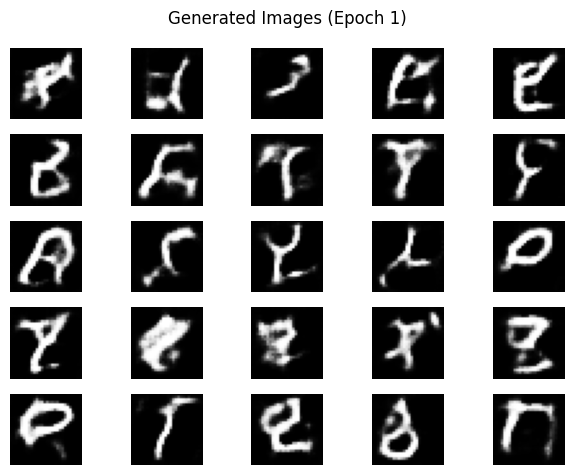


Epoch 2/40
Generator Loss: -11.2573, Discriminator Loss: -1.0080
Precision: 0.3362, Recall: 0.3008


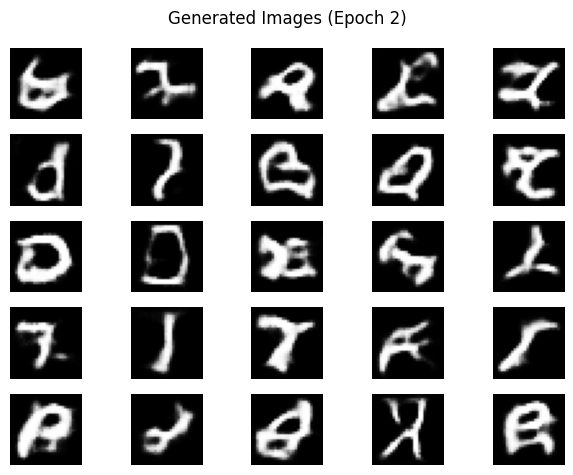


Epoch 3/40
Generator Loss: -10.1985, Discriminator Loss: -0.9588
Precision: 0.3233, Recall: 0.2930


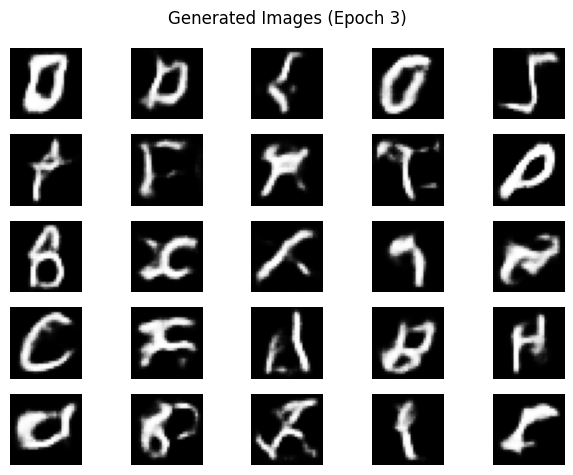


Epoch 4/40
Generator Loss: -8.8285, Discriminator Loss: -0.9356
Precision: 0.4545, Recall: 0.4102


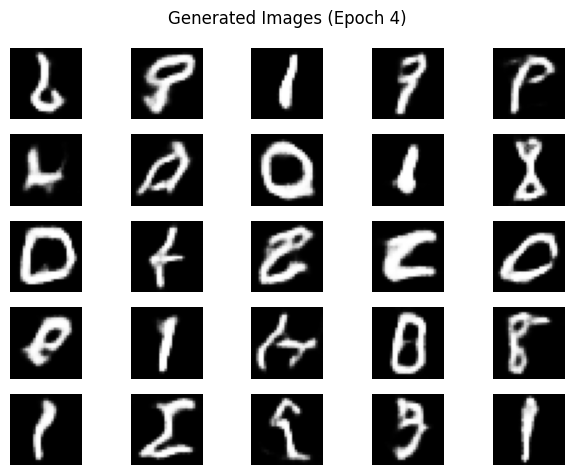


Epoch 5/40
Generator Loss: -7.8424, Discriminator Loss: -0.9518
Precision: 0.4848, Recall: 0.5000


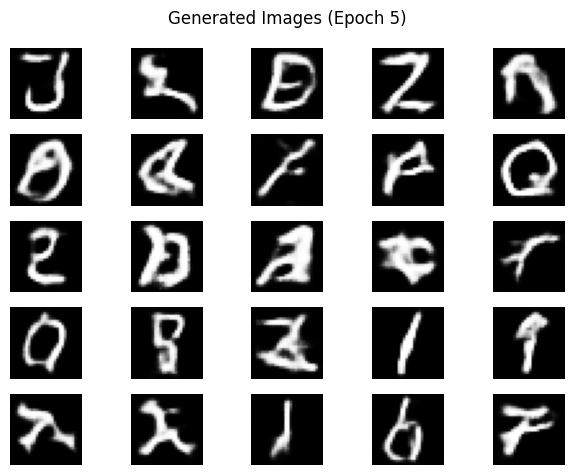


Epoch 6/40
Generator Loss: -7.3114, Discriminator Loss: -0.8935
Precision: 0.6204, Recall: 0.5234


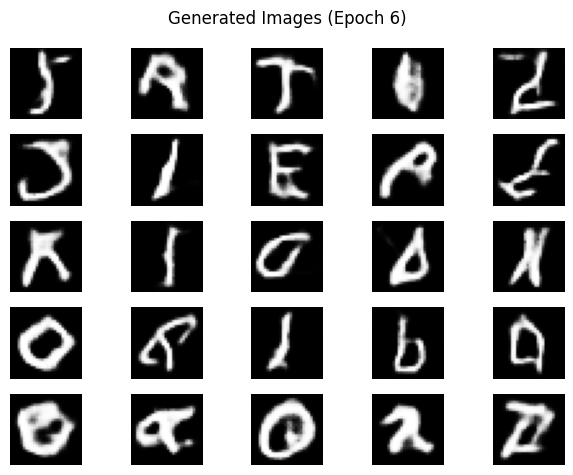


Epoch 7/40
Generator Loss: -7.0103, Discriminator Loss: -0.8988
Precision: 0.5022, Recall: 0.4375


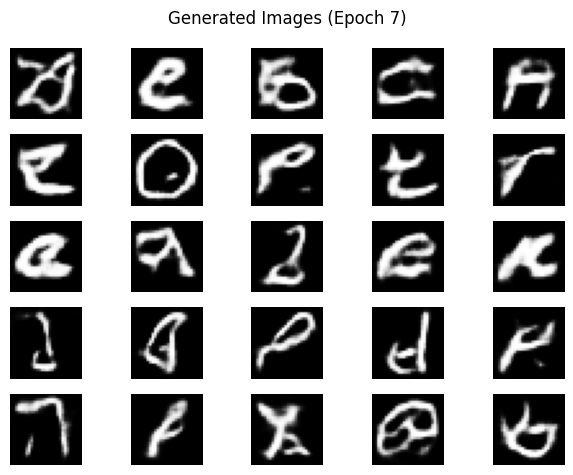


Epoch 8/40
Generator Loss: -6.9930, Discriminator Loss: -0.8721
Precision: 0.7186, Recall: 0.6484


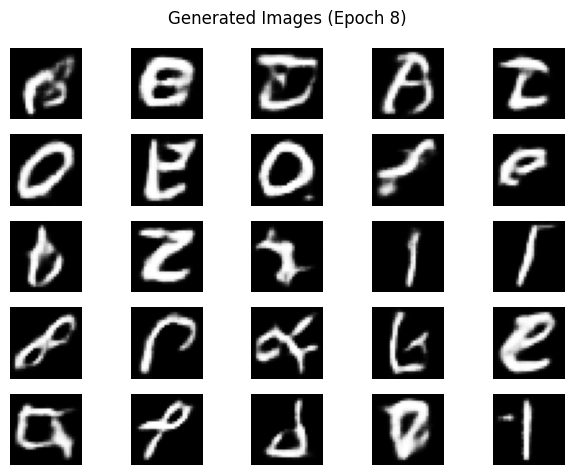


Epoch 9/40
Generator Loss: -6.6476, Discriminator Loss: -0.9100
Precision: 0.5066, Recall: 0.4531


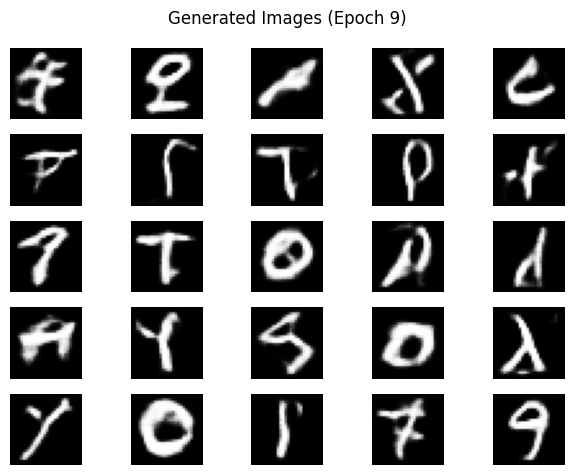


Epoch 10/40
Generator Loss: -6.0942, Discriminator Loss: -0.8775
Precision: 0.4905, Recall: 0.5039


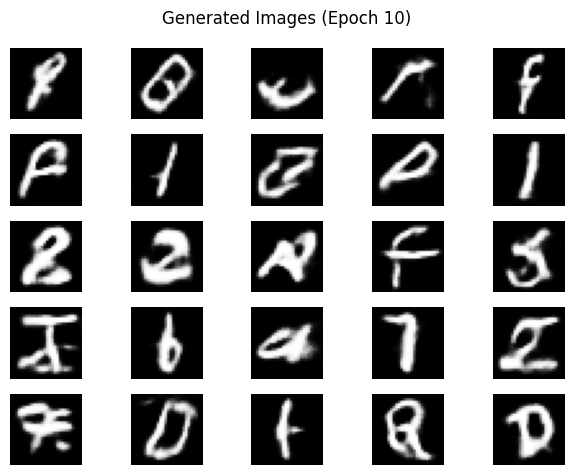


Epoch 11/40
Generator Loss: -6.0492, Discriminator Loss: -0.8950
Precision: 0.3507, Recall: 0.2891


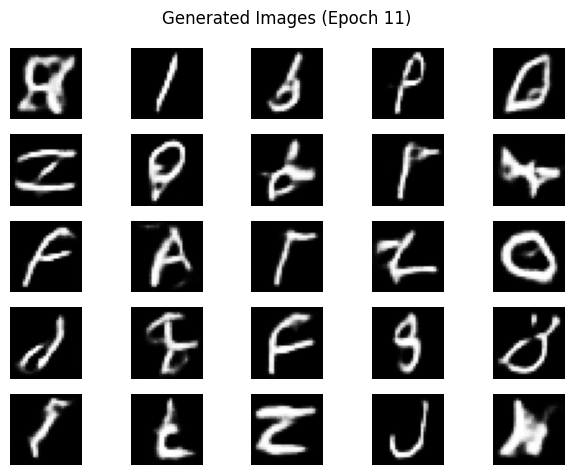


Epoch 12/40
Generator Loss: -5.6532, Discriminator Loss: -0.8912
Precision: 0.5063, Recall: 0.4687


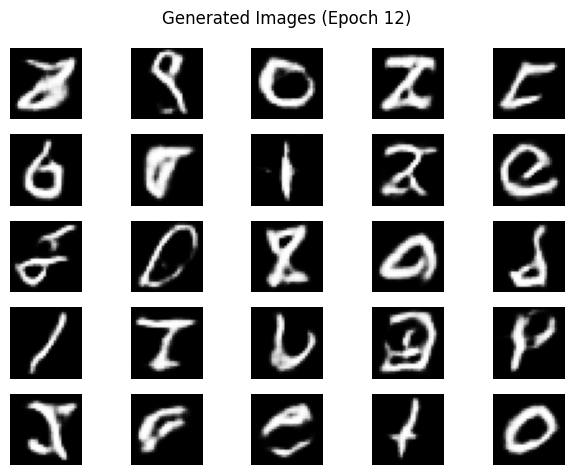


Epoch 13/40
Generator Loss: -4.9964, Discriminator Loss: -0.8309
Precision: 0.5546, Recall: 0.5156


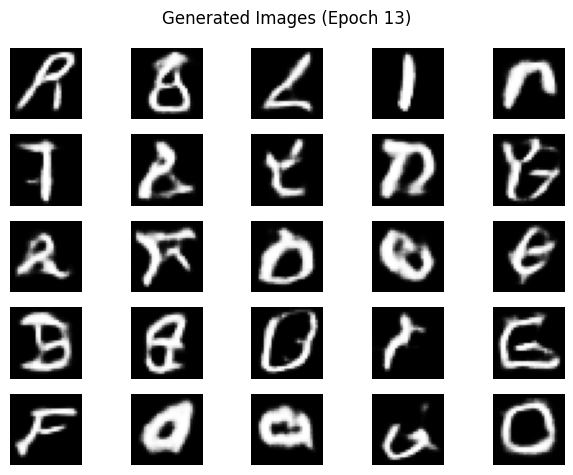


Epoch 14/40
Generator Loss: -4.4578, Discriminator Loss: -0.8694
Precision: 0.8033, Recall: 0.7656


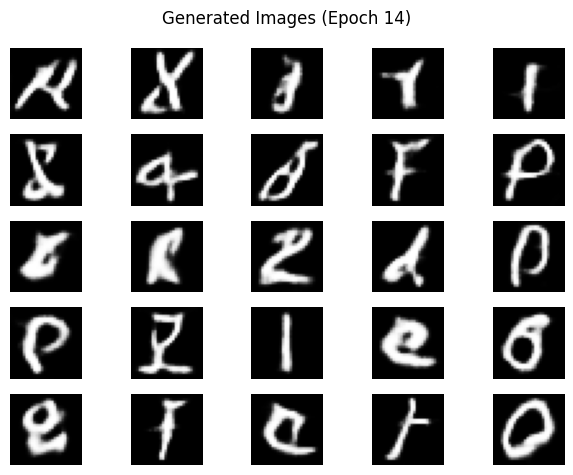


Epoch 15/40
Generator Loss: -4.4761, Discriminator Loss: -0.8452
Precision: 0.4389, Recall: 0.3789


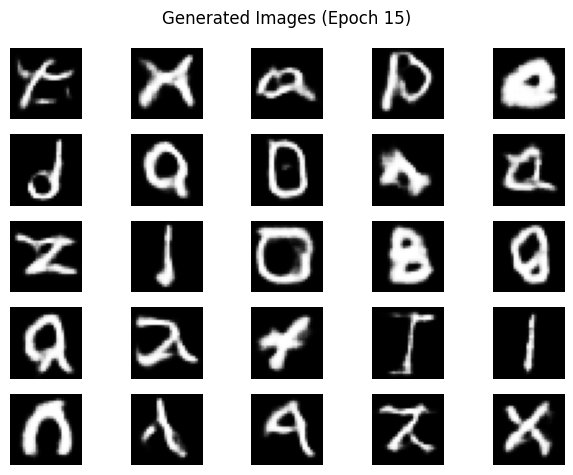


Epoch 16/40
Generator Loss: -4.7541, Discriminator Loss: -0.8015
Precision: 0.3184, Recall: 0.3047


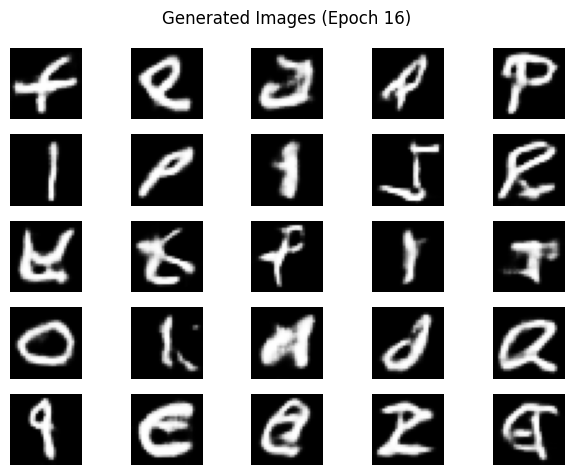


Epoch 17/40
Generator Loss: -4.1346, Discriminator Loss: -0.8143
Precision: 0.4468, Recall: 0.4102


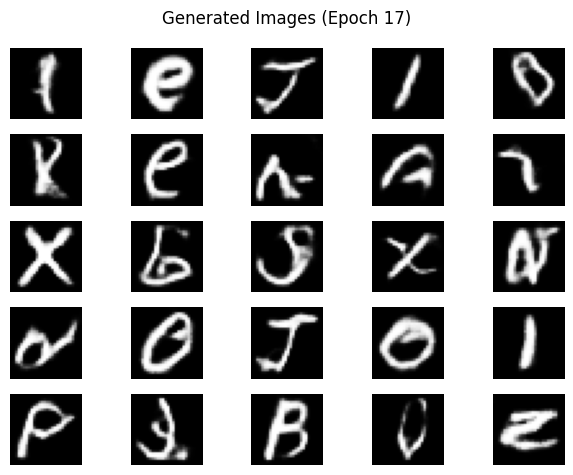


Epoch 18/40
Generator Loss: -4.2407, Discriminator Loss: -0.8229
Precision: 0.4978, Recall: 0.4414


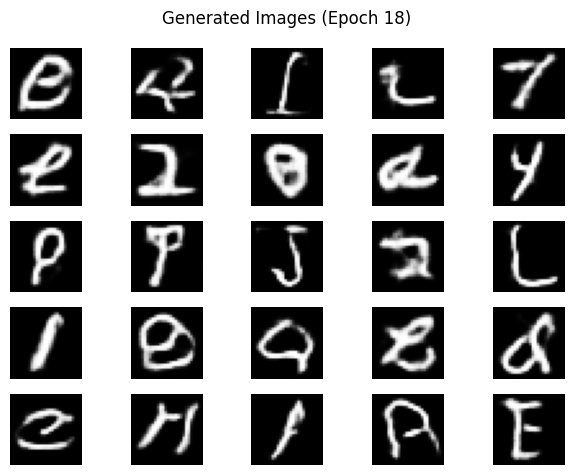


Epoch 19/40
Generator Loss: -4.4708, Discriminator Loss: -0.7577
Precision: 0.2839, Recall: 0.2617


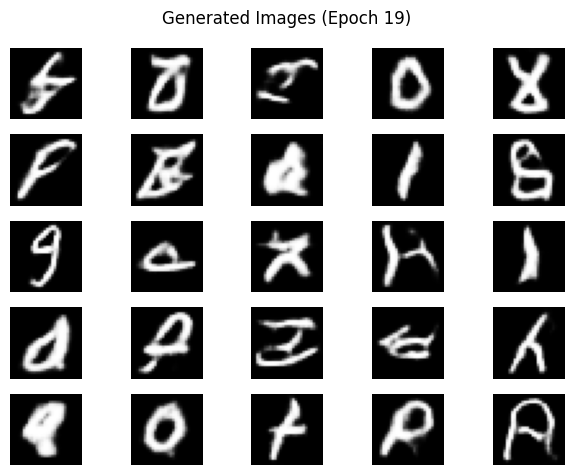


Epoch 20/40
Generator Loss: -4.3777, Discriminator Loss: -0.7646
Precision: 0.5721, Recall: 0.4961


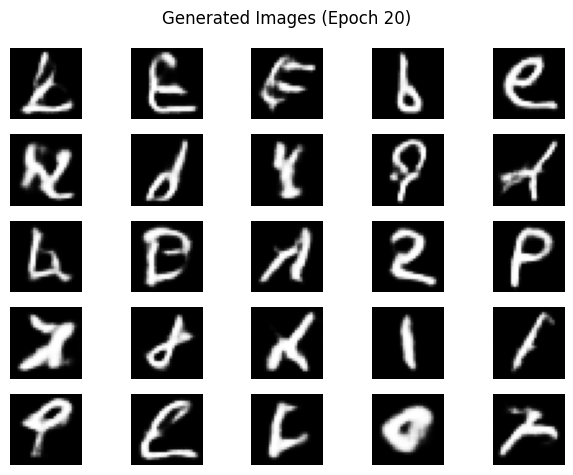


Epoch 21/40
Generator Loss: -3.9252, Discriminator Loss: -0.8075
Precision: 0.5477, Recall: 0.5156


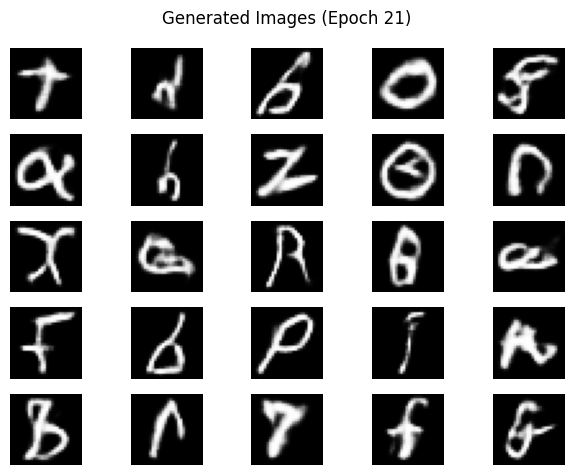


Epoch 22/40
Generator Loss: -3.8051, Discriminator Loss: -0.7840
Precision: 0.5845, Recall: 0.5000


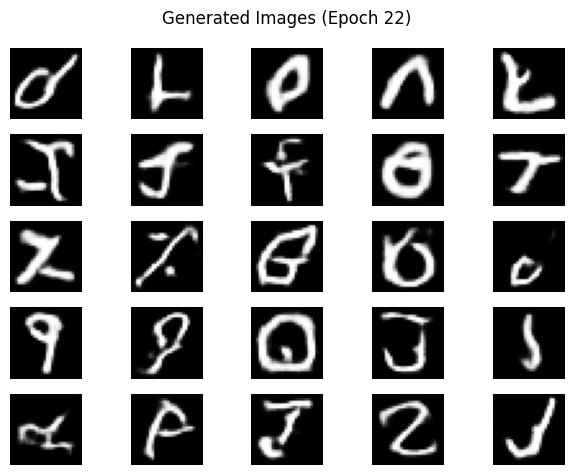


Epoch 23/40
Generator Loss: -3.5603, Discriminator Loss: -0.7569
Precision: 0.3019, Recall: 0.2500


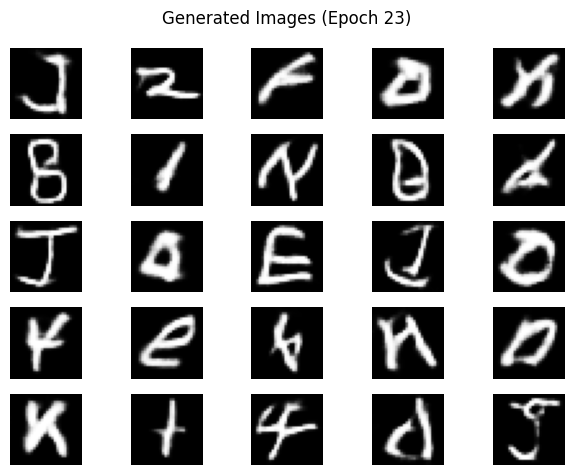


Epoch 24/40
Generator Loss: -3.5160, Discriminator Loss: -0.7634
Precision: 0.7673, Recall: 0.7344


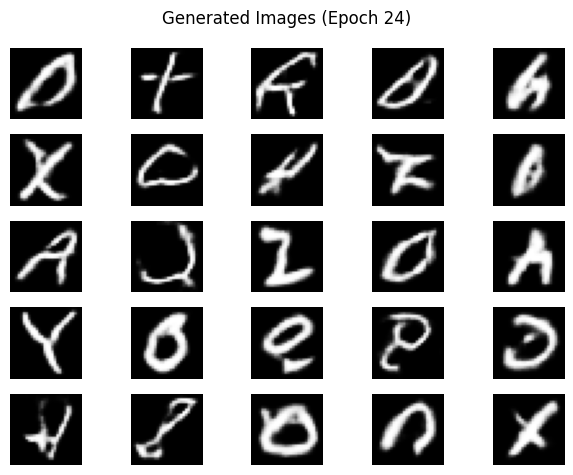


Epoch 25/40
Generator Loss: -3.4345, Discriminator Loss: -0.7660
Precision: 0.2846, Recall: 0.2734


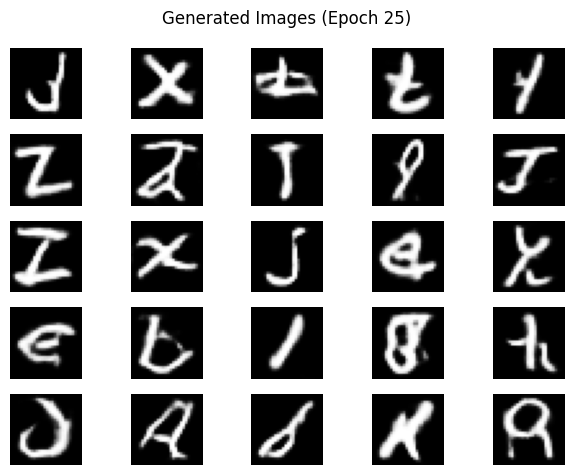


Epoch 26/40
Generator Loss: -2.1199, Discriminator Loss: -0.7228
Precision: 0.4917, Recall: 0.4648


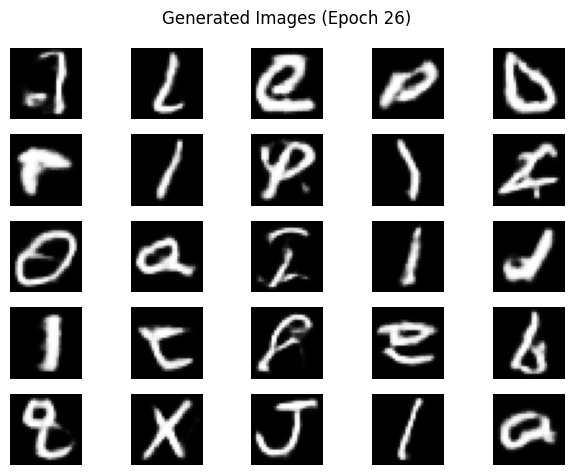


Epoch 27/40
Generator Loss: -2.6381, Discriminator Loss: -0.7126
Precision: 0.5882, Recall: 0.5469


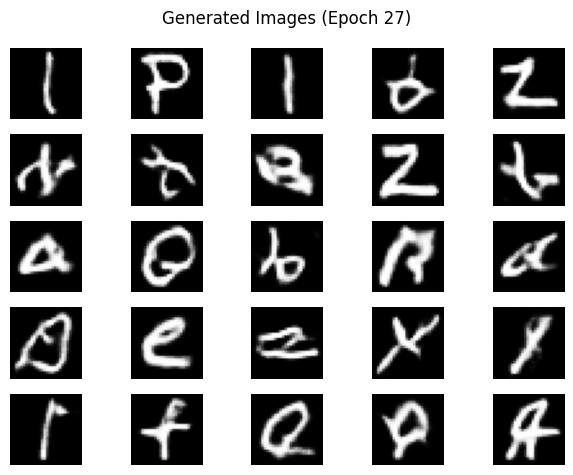


Epoch 28/40
Generator Loss: -2.4065, Discriminator Loss: -0.7010
Precision: 0.7607, Recall: 0.6953


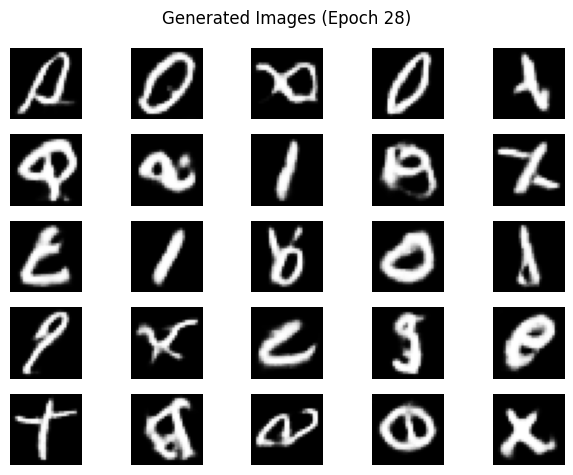


Epoch 29/40
Generator Loss: -3.0247, Discriminator Loss: -0.7107
Precision: 0.5465, Recall: 0.5508


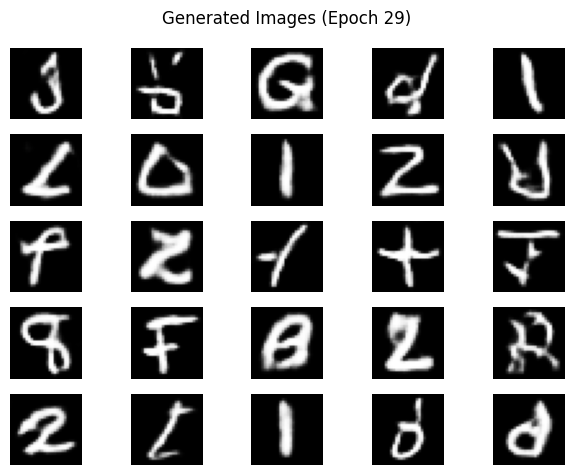


Epoch 30/40
Generator Loss: -2.2889, Discriminator Loss: -0.7181
Precision: 0.4249, Recall: 0.3867


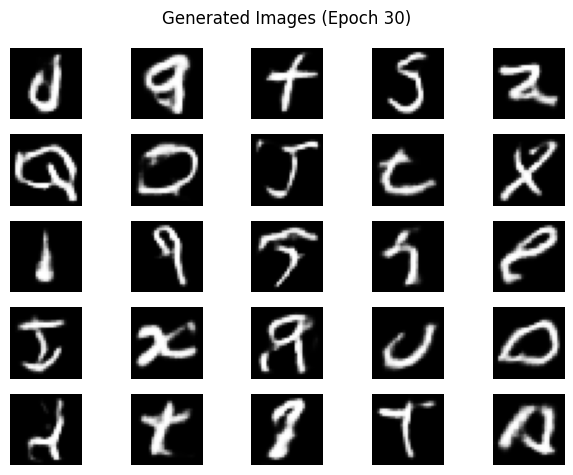


Epoch 31/40
Generator Loss: -3.1928, Discriminator Loss: -0.6787
Precision: 0.2455, Recall: 0.2109


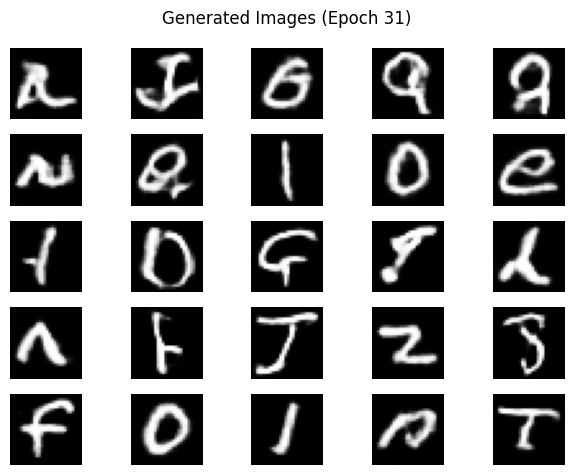


Epoch 32/40
Generator Loss: -3.5650, Discriminator Loss: -0.6850
Precision: 0.2982, Recall: 0.2656


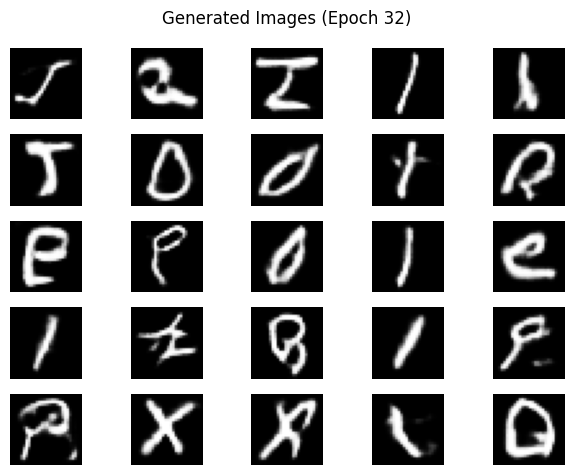


Epoch 33/40
Generator Loss: -3.3866, Discriminator Loss: -0.6898
Precision: 0.5166, Recall: 0.4258


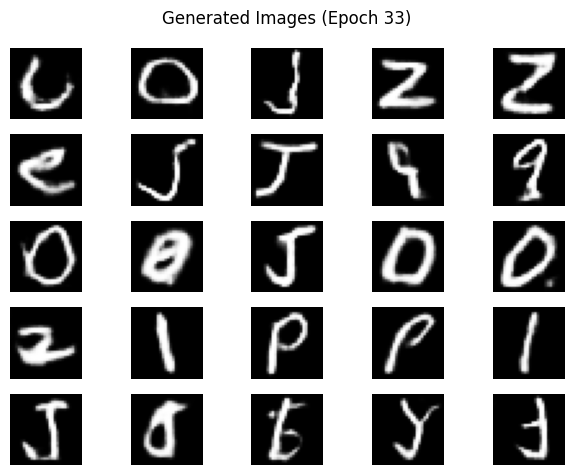


Epoch 34/40
Generator Loss: -2.8979, Discriminator Loss: -0.6734
Precision: 0.2569, Recall: 0.2539


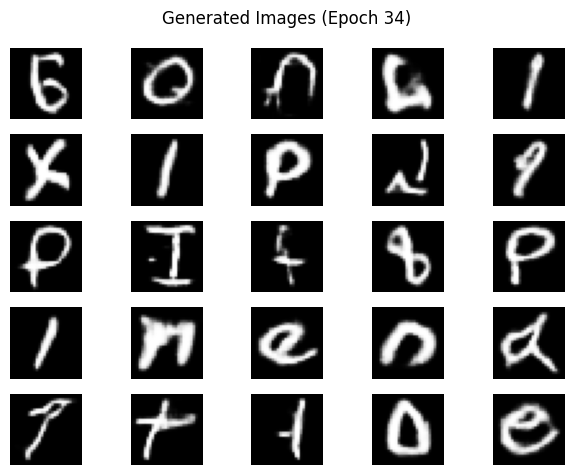


Epoch 35/40
Generator Loss: -2.2523, Discriminator Loss: -0.6731
Precision: 0.5265, Recall: 0.5430


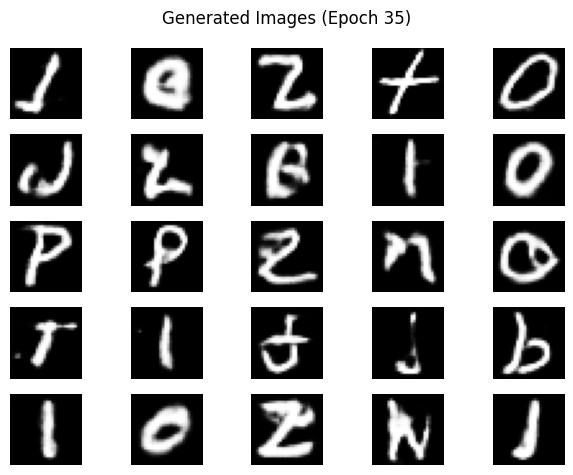


Epoch 36/40
Generator Loss: -2.6644, Discriminator Loss: -0.6549
Precision: 0.5714, Recall: 0.6094


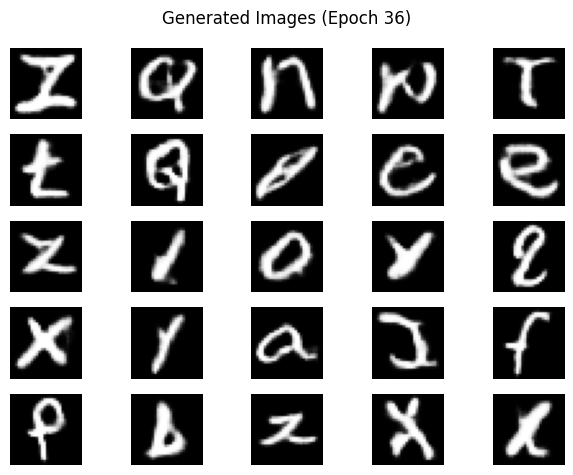


Epoch 37/40
Generator Loss: -3.2498, Discriminator Loss: -0.6703
Precision: 0.4906, Recall: 0.5078


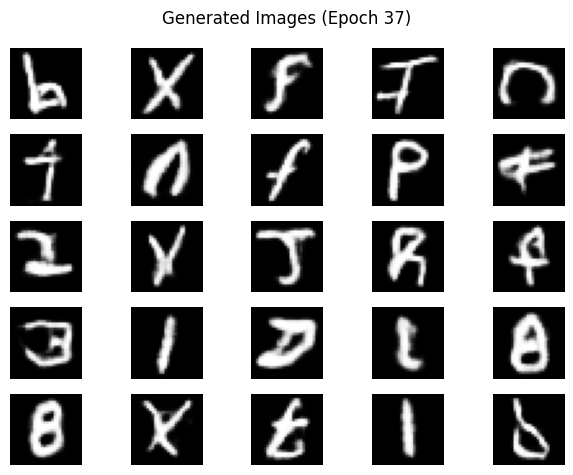


Epoch 38/40
Generator Loss: -3.4640, Discriminator Loss: -0.6417
Precision: 0.4571, Recall: 0.4375


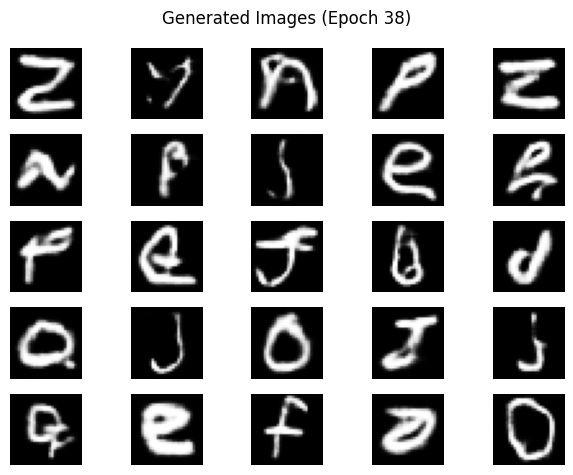


Epoch 39/40
Generator Loss: -2.4287, Discriminator Loss: -0.6592
Precision: 0.6382, Recall: 0.6133


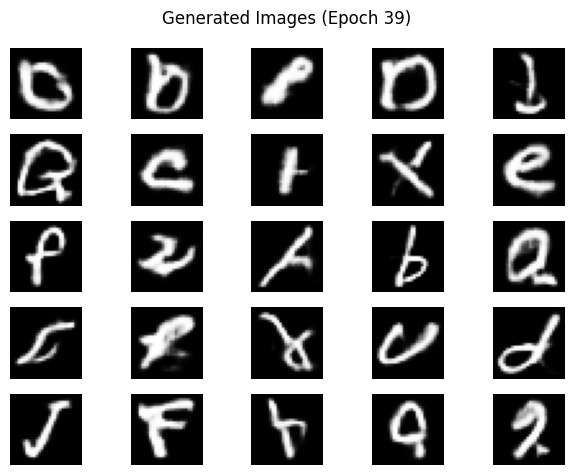


Epoch 40/40
Generator Loss: -2.7857, Discriminator Loss: -0.6269
Precision: 0.3846, Recall: 0.3711


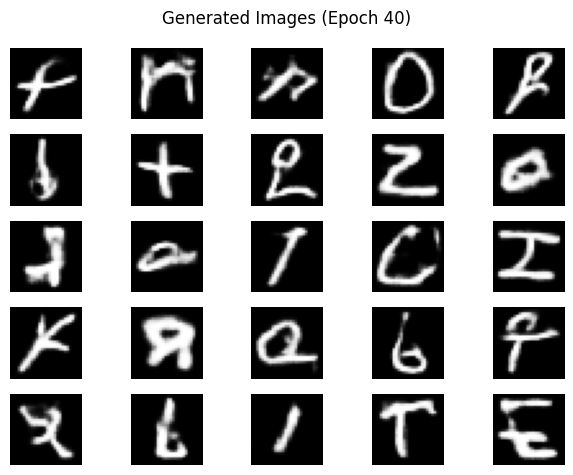

===== Final GAN Evaluation =====
Epoch: 40
Avg Discriminator Confidence: 2.1636
Real Images - Mean: 0.1710, Std: 0.3303
Fake Images - Mean: 0.1767, Std: 0.3313
FID Score: 36559.4643


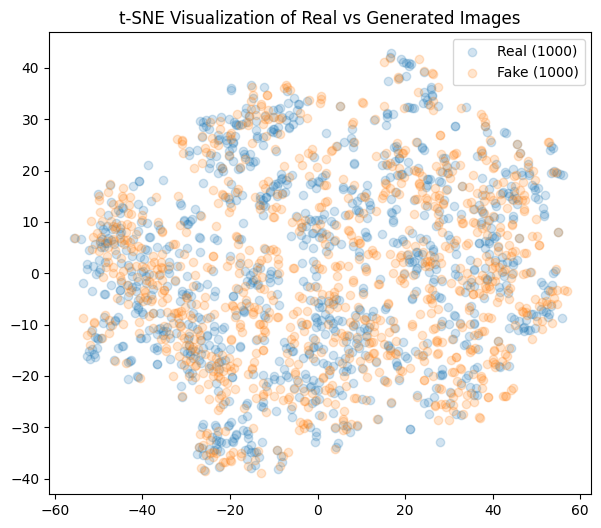

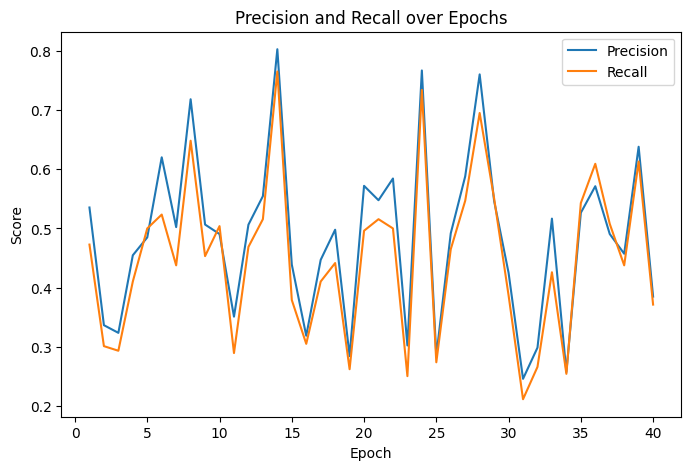

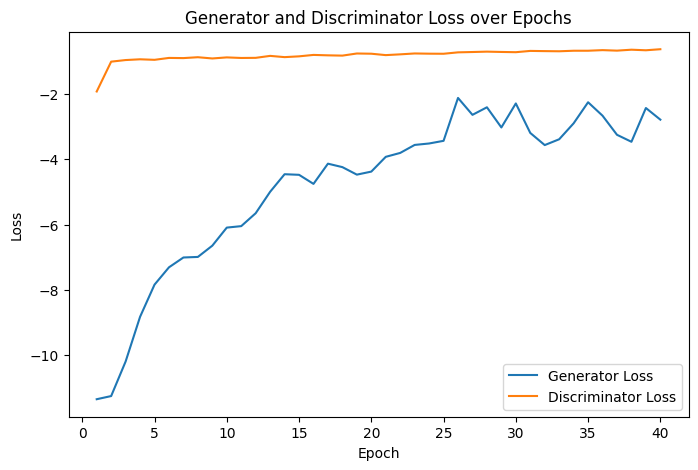

In [234]:
# === Hyperparameters ===
EPOCHS = 40
noise_dim = 256
BATCH_SIZE = 64
CRITIC_ITERATIONS = 5
LAMBDA_GP = 10.0

gen_loss_history = []
disc_loss_history = []
precision_history = []
recall_history = []

# === Optimizers ===
generator_optimizer = tf.keras.optimizers.Adam(1e-4, beta_1=0.0, beta_2=0.9)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4, beta_1=0.0, beta_2=0.9)

# === Create models ===
generator = make_generator_model()
discriminator = make_discriminator_model()

# === Seed for evaluation (e.g., t-SNE, metrics) ===
eval_seed = tf.random.normal([1000, noise_dim])

@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]
    # Update discriminator (critic) multiple times
    for _ in range(CRITIC_ITERATIONS):
        noise = tf.random.normal([batch_size, noise_dim])
        with tf.GradientTape() as disc_tape:
            fake_images = generator(noise, training=True)
            real_output = discriminator(real_images, training=True)
            fake_output = discriminator(fake_images, training=True)
            gp = gradient_penalty(discriminator, real_images, fake_images)
            disc_loss = discriminator_loss(real_output, fake_output, gp, LAMBDA_GP)
        gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)
        discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    # Update generator once
    noise = tf.random.normal([batch_size, noise_dim])
    with tf.GradientTape() as gen_tape:
        generated_images = generator(noise, training=True)
        fake_output = discriminator(generated_images, training=True)
        gen_loss = generator_loss(fake_output)
    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))

    return gen_loss, disc_loss

def train(dataset, epochs, real_images):
    for epoch in range(epochs):
        print(f"\nEpoch {epoch + 1}/{epochs}")

        epoch_gen_loss = []
        epoch_disc_loss = []

        for image_batch in dataset:
            gen_loss, disc_loss = train_step(image_batch)
            epoch_gen_loss.append(gen_loss.numpy())
            epoch_disc_loss.append(disc_loss.numpy())

        # Record average losses
        avg_gen_loss = np.mean(epoch_gen_loss)
        avg_disc_loss = np.mean(epoch_disc_loss)

        gen_loss_history.append(avg_gen_loss)
        disc_loss_history.append(avg_disc_loss)

        print(f"Generator Loss: {avg_gen_loss:.4f}, Discriminator Loss: {avg_disc_loss:.4f}")

        # Evaluate precision & recall
        noise = tf.random.normal([min(256, len(real_images)), noise_dim])
        fake_images = generator(noise, training=False)
        real_subset = real_images[:fake_images.shape[0]]
        precision, recall = calculate_precision_recall(discriminator, real_subset, fake_images)
        precision_history.append(precision)
        recall_history.append(recall)

        print(f"Precision: {precision:.4f}, Recall: {recall:.4f}")

        show_generated_images(generator, noise_dim, epoch + 1)

    # Run full evaluation after training
    evaluate_gan(generator, discriminator, noise_dim, real_images, epoch=epochs, seed_noise=eval_seed,
                 precision_history=precision_history, recall_history=recall_history,
                 gen_loss_history=gen_loss_history, disc_loss_history=disc_loss_history)

# Start training
train(train_dataset, EPOCHS, real_images=X_filtered)